# Gene report: ClinVar variants → regulation and structure

This notebook runs `var2fold` for **any human gene**:

1. **ClinVar** gives the known pathogenic variants of the gene (most trusted review status first).
2. **Ensembl VEP** annotates each one (consequence, residue, gnomAD).
3. **AlphaGenome** scores the predicted effect on expression, splicing and accessibility.
4. **AlphaFold DB** places each variant on the protein structure, with **UniProt** domains.

Run it for another gene with [papermill](https://papermill.readthedocs.io):

```bash
papermill notebooks/gene_report.ipynb results/BRCA1_report.ipynb -p gene BRCA1 -p max_variants 15
```

Every number and sentence below is computed from the data. The *How to read this* section at the end explains what the scores do and do not mean.

In [1]:
gene = "TP53"                   # HGNC symbol
consequence = "missense"        # missense | coding | splice | any
significance = "pathogenic,likely_pathogenic"
max_variants = 10               # most trusted ClinVar variants; each costs AlphaGenome calls
conditions = ["UBERON:0001157"] # tissue / cell type (CURIEs); first one is used for figures
sequence_length = 1_048_576     # AlphaGenome context window
use_alphagenome = True          # False: annotation + structure only, no key needed
out_dir = "results/gene_reports"


In [2]:
# Parameters
gene = "BRCA1"
max_variants = 10
out_dir = "results/gene_reports"


In [3]:
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from var2fold.alphafold_client import AlphaFoldClient
from var2fold.clinvar import write_vcf
from var2fold.config import Settings
from var2fold.pipeline import GenomeToStructurePipeline, batch_findings, batch_table
from var2fold.plots import effects_panels, plddt_profile

logging.basicConfig(level=logging.WARNING)
warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(ROOT)  # .env, .cache/ and data/ are resolved from the project root
OUT = ROOT / out_dir
OUT.mkdir(parents=True, exist_ok=True)

pipeline = GenomeToStructurePipeline(
    Settings.from_env(), use_alphagenome=use_alphagenome, sequence_length=sequence_length
)

## 1. Known pathogenic variants (ClinVar)

In [4]:
selection, results = pipeline.run_gene(
    gene,
    conditions,
    consequence=consequence,
    significance=[s.strip() for s in significance.split(",")],
    max_variants=max_variants,
    score=use_alphagenome,
)
vcf_path = write_vcf(selection, OUT / f"{gene}_clinvar_{consequence}.vcf")
shown = vcf_path.relative_to(ROOT) if vcf_path.is_relative_to(ROOT) else vcf_path
print(f"Selection saved to {shown} (re-run it with: var2fold vcf ...)")
pd.DataFrame(
    {
        "label": cv.label,
        "variant": str(cv.variant),
        "classification": cv.classification,
        "review stars": cv.stars,
        "consequence": ", ".join(cv.consequences),
        "ClinVar": cv.accession,
    }
    for cv in selection
)

Selection saved to results/gene_reports/BRCA1_clinvar_missense.vcf (re-run it with: var2fold vcf ...)


,label,variant,classification,review stars,consequence,ClinVar
0,W1837G,chr17:43045761:A>C,Pathogenic,3,"missense variant, 3 prime UTR variant, non-cod...",VCV000055607
1,L1786P,chr17:43049170:A>G,Pathogenic,3,"missense variant, non-coding transcript varian...",VCV000091649
2,G1770V,chr17:43051086:C>A,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000417832
3,G1738R,chr17:43057117:C>T,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000055461
4,A1708E,chr17:43063903:G>T,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000055407
5,D1692H,chr17:43067608:C>G,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000037633
6,E1559K,chr17:43074331:C>T,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000037604
7,C61G,chr17:43106487:A>C,Pathogenic,3,"missense variant, non-coding transcript variant",VCV000017661
8,C44S,chr17:43115730:A>T,Pathogenic,3,"missense variant, non-coding transcript varian...",VCV000054191
9,L22S,chr17:43124032:A>G,Pathogenic,3,"missense variant, 5 prime UTR variant, non-cod...",VCV000055656


## 2. Annotation, structure and AlphaGenome scores

In [5]:
table = batch_table(results)
table.to_csv(OUT / f"{gene}_clinvar_{consequence}_summary.csv", index=False)
cols = ["vcf_id", "variant", "consequence", "protein_change", "gnomad_af", "residue_plddt",
        "rna_lfc", "splicing", "accessibility", "warnings"]
table[[c for c in cols if c in table and table[c].notna().any()]]

,vcf_id,variant,consequence,protein_change,gnomad_af,residue_plddt,rna_lfc,splicing,accessibility
0,W1837G,chr17:43045761:A>C,missense_variant,W/G@1837,NaN,96.69,-0.009,0.058,0.014
1,L1786P,chr17:43049170:A>G,missense_variant,L/P@1786,NaN,94.25,-0.012,0.069,0.108
2,G1770V,chr17:43051086:C>A,missense_variant,G/V@1770,1.368e-06,84.94,0.014,0.156,-0.034
3,G1738R,chr17:43057117:C>T,missense_variant,G/R@1738,NaN,94.69,0.008,0.090,-0.016
4,A1708E,chr17:43063903:G>T,missense_variant,A/E@1708,4.789e-06,96.12,-0.014,2.828,-0.192
5,D1692H,chr17:43067608:C>G,missense_variant&splice_region_variant,D/H@1692,2.751e-06,94.06,-0.017,9.625,-0.023
6,E1559K,chr17:43074331:C>T,missense_variant&splice_region_variant,E/K@1559,6.574e-06,28.28,-0.009,8.312,0.034
7,C61G,chr17:43106487:A>C,missense_variant,C/G@61,3.285e-05,87.56,-0.010,1.111,0.031
8,C44S,chr17:43115730:A>T,missense_variant,C/S@44,NaN,93.31,-0.012,0.232,-0.023
9,L22S,chr17:43124032:A>G,missense_variant,L/S@22,NaN,90.81,-0.007,0.220,0.041


## 3. Where do the variants sit on the protein?

AlphaFold's per-residue confidence (pLDDT) along the sequence, the variants analysed, and the UniProt domain architecture underneath.

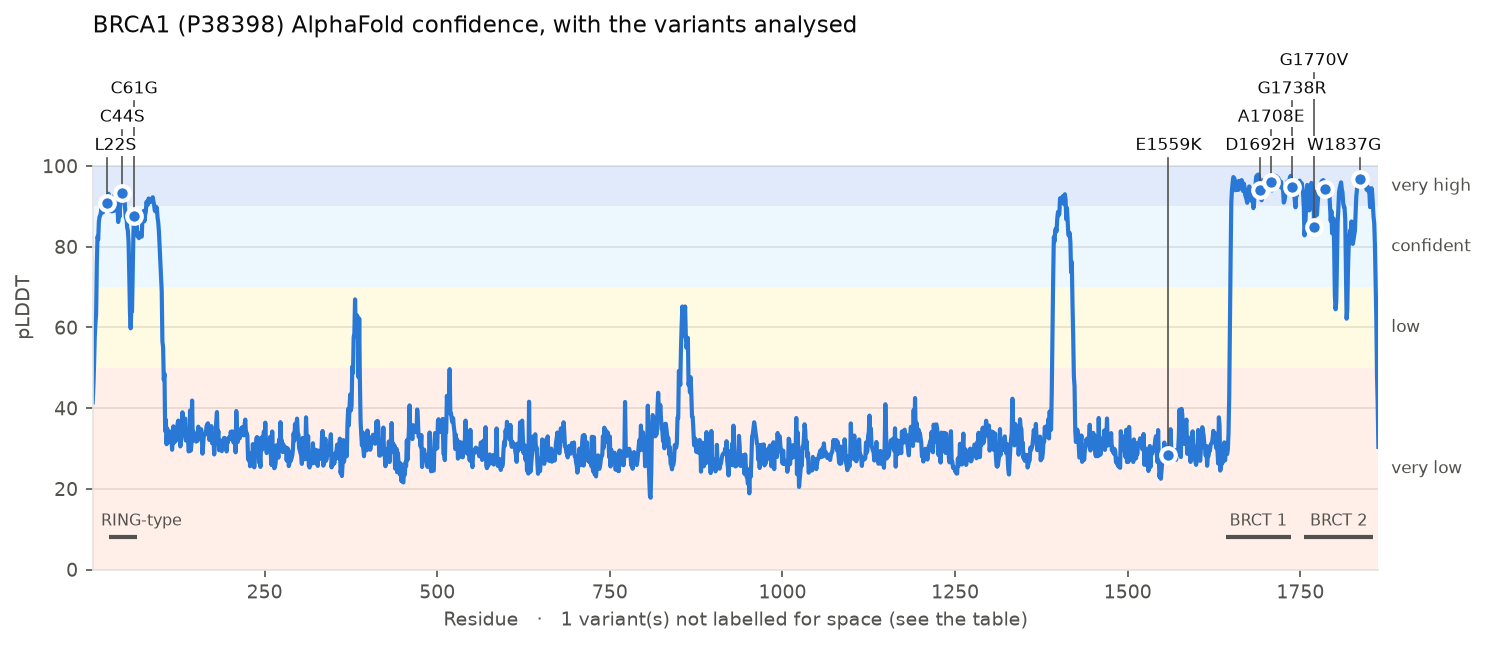

In [6]:
with_structure = [r for r in results if r.structures]
if not with_structure:
    display(Markdown("_No AlphaFold structure for these variants "
                     "(non-coding, or no model in AlphaFold DB)._"))
else:
    s0 = with_structure[0].structures[0]
    plddt = AlphaFoldClient.residue_plddt(Path(s0.structure_path))
    offset = (s0.entry.uniprot_start or 1) - 1  # fragment entries start later in the sequence
    plddt = {res + offset: v for res, v in plddt.items()}
    variants = {
        r.vcf_id or r.query: r.structures[0].residue
        for r in with_structure
        if r.structures[0].entry.entry_id == s0.entry.entry_id and r.structures[0].residue
    }
    domains = pipeline.mapper.protein_features(s0.entry.uniprot_accession)
    fig = plddt_profile(
        plddt, variants, domains,
        title=f"{gene} ({s0.entry.uniprot_accession}) AlphaFold confidence, "
        "with the variants analysed",
    )
    fig.savefig(OUT / f"{gene}_plddt_profile.png", bbox_inches="tight")
    plt.show()

## 4. Predicted regulatory effects (AlphaGenome)

One representative scorer per panel (strongest signed effect over the tracks of the first condition). Scorers have different scales: compare variants **within** a panel, never across panels.

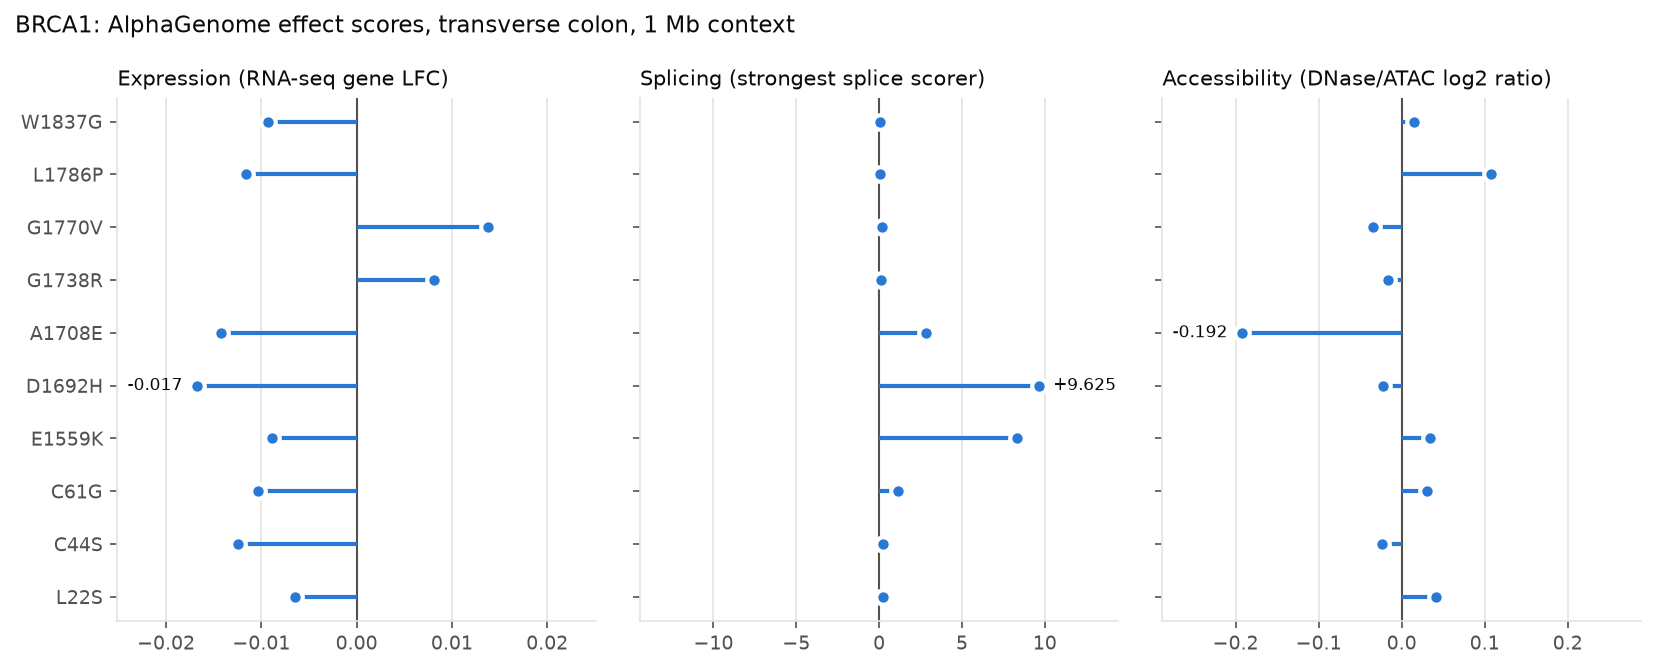

In [7]:
scored = table.dropna(subset=["condition"]) if "condition" in table else table.iloc[0:0]
if scored.empty:
    display(Markdown("_AlphaGenome was not run (`use_alphagenome = False`)._"))
else:
    first = scored[scored["condition"] == scored["condition"].iloc[0]]
    window = "1 Mb" if sequence_length == 1_048_576 else f"{sequence_length // 1024} kb"
    fig = effects_panels(
        first.assign(label=first["vcf_id"].fillna(first["variant"])),
        title=f"{gene}: AlphaGenome effect scores, {first['condition'].iloc[0]}, {window} context",
    )
    fig.savefig(OUT / f"{gene}_effects.png", bbox_inches="tight")
    plt.show()

## 5. What the data say

In [8]:
display(Markdown("\n".join(f"* {line}" for line in batch_findings(table))))

* 10 variant(s) analysed.
* AlphaFold confidence at the mutated residue (10 with a structure): 7 very high (>90), 2 confident (70-90), 1 low or very low (<=70); median pLDDT 93.7.
* Strongest expression effect (RNA-seq gene LFC): D1692H (-0.017); median |score| 0.011 across 10 variant(s).
* Strongest splicing effect: D1692H (+9.625); median |score| 0.226 across 10 variant(s). Of the top 3, D1692H, E1559K are annotated by VEP as splice-region variant(s), an independent hint that the score is not noise.
* Strongest accessibility effect (DNase/ATAC): A1708E (-0.192); median |score| 0.032 across 10 variant(s).

## How to read this

* **pLDDT is confidence in the predicted structure, not the mutation's effect.** A variant in a high-pLDDT region sits in a well-folded part of the protein, where a substitution can disrupt folding or a binding surface. A **low pLDDT does not mean unimportant**: flexible loops can be functional switches (BRAF V600E sits in a low-confidence activation loop).
* **AlphaGenome scores are raw model predictions without calibrated thresholds.** Compare variants within one scorer, not across scorers. Coding missense variants usually get small regulatory scores, because the model sees DNA, not protein function. Splice-region and non-coding variants (`consequence = "splice"` or `"any"`) are where AlphaGenome is most informative.
* **The selection is ranked by ClinVar review status**, then by position, so it is not a random sample of the gene's variants. Raise `max_variants` to cover more of the protein.
* **External databases change** (ClinVar monthly, Ensembl quarterly, AlphaFold DB model versions). Re-running later can give a different selection; the saved VCF lets you re-run the exact same variants.
* This is a research tool for a first look at a set of variants, **not a clinical classifier**.